Last Updated: Fall 2026

In [ ]:
pip install trimesh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.4/750.4 kB 20.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import plotly.graph_objects as go
import cv2
import trimesh
from shapely.geometry import Polygon, LineString
from skimage import measure
from scipy.ndimage import distance_transform_edt, gaussian_filter

# ==========================================
# 1. PARAMETERS
# ==========================================
NOZZLE_DIA = 0.5
LAYER_HEIGHT = 0.175
RESOLUTION = 0.02
CONTOUR_LEVELS = 16
GEOMETRIC_BIAS = 0.05

def density_function(x, y, z):
    # Volumetric density - you can now vary based on the Y-height as well
    raw_field = np.sin(x / 2) * np.cos(z / 2) + x/4 + (z**2)/25 + np.sin(y)*np.sin(x / 2)
    raw_field = np.where(raw_field > 0.5, 1.0, raw_field)
    return raw_field

# ==========================================
# 2. GAP FILL ENGINE
# ==========================================
def generate_gap_fill(existing_lines, poly, res, nozzle):
    minx, miny, maxx, maxy = poly.bounds
    pad = 1.0
    width = int((maxx - minx + 2*pad) / res)
    height = int((maxy - miny + 2*pad) / res)

    mask = np.zeros((height, width), dtype=np.uint8)
    if poly.exterior is None: return []

    poly_x, poly_y = poly.exterior.xy
    pix_px = ((np.array(poly_x) - (minx - pad)) / res).astype(int)
    pix_py = ((np.array(poly_y) - (miny - pad)) / res).astype(int)
    poly_pixel_pts = np.column_stack((pix_px, pix_py)).reshape((-1, 1, 2))
    cv2.fillPoly(mask, [poly_pixel_pts], color=255)

    canvas = np.zeros((height, width), dtype=np.uint8)
    for line in existing_lines:
        pts = np.array(line)
        pix_x = ((pts[:, 0] - (minx - pad)) / res).astype(int)
        pix_y = ((pts[:, 1] - (miny - pad)) / res).astype(int)
        pixel_pts = np.column_stack((pix_x, pix_y)).reshape((-1, 1, 2))
        cv2.polylines(canvas, [pixel_pts], isClosed=False, color=255, thickness=1)

    empty_space = ((mask == 255) & (canvas == 0)).astype(np.uint8)
    dist_field = distance_transform_edt(empty_space) * res

    gap_lines = []
    max_gap = np.max(dist_field)
    gap_levels = list(np.arange(nozzle, max_gap, nozzle))
    if gap_levels: remainder = max_gap - gap_levels[-1]
    else: remainder = max_gap

    if remainder >= (nozzle / 2.0): gap_levels.append(max_gap - (res * 1.5))

    for lvl in gap_levels:
        contours = measure.find_contours(dist_field, lvl)
        for c in contours:
            path_x = minx - pad + (c[:, 1] * res)
            path_y = miny - pad + (c[:, 0] * res)
            line = LineString(np.column_stack((path_x, path_y)))
            intersection = poly.intersection(line)
            if intersection.is_empty: continue
            elif intersection.geom_type == 'LineString': gap_lines.append(list(intersection.coords))
            elif intersection.geom_type == 'MultiLineString':
                for geom in intersection.geoms: gap_lines.append(list(geom.coords))
    return [line for line in gap_lines if len(line) > 2]

# ==========================================
# 3. MAIN 2D SLICER (Decoupled from 3D axes)
# ==========================================
def generate_adaptive_isocontour_infill(poly, res, density_func, num_levels, nozzle):
    minx, miny, maxx, maxy = poly.bounds
    pad = 1.0
    x = np.arange(minx - pad, maxx + pad, res)
    y = np.arange(miny - pad, maxy + pad, res)
    xx, yy = np.meshgrid(x, y)

    math_field = density_func(xx, yy)

    width_px, height_px = xx.shape[1], xx.shape[0]
    mask = np.zeros((height_px, width_px), dtype=np.uint8)
    poly_x, poly_y = poly.exterior.xy

    pix_px = ((np.array(poly_x) - (minx - pad)) / res).astype(int)
    pix_py = ((np.array(poly_y) - (miny - pad)) / res).astype(int)
    poly_pixel_pts = np.column_stack((pix_px, pix_py)).reshape((-1, 1, 2))
    cv2.fillPoly(mask, [poly_pixel_pts], color=255)

    geom_dist = distance_transform_edt(mask) * res
    m_min, m_max = np.min(math_field), np.max(math_field)
    math_norm = (math_field - m_min) / (m_max - m_min + 1e-9)
    g_min, g_max = np.min(geom_dist), np.max(geom_dist)
    geom_norm = (geom_dist - g_min) / (g_max - g_min + 1e-9)

    z_field = (1.0 - GEOMETRIC_BIAS) * math_norm + (GEOMETRIC_BIAS) * geom_norm
    z_field_smoothed = gaussian_filter(z_field, sigma=1.0)

    gy, gx = np.gradient(z_field_smoothed, res, res)
    grad_mag = np.clip(np.sqrt(gx**2 + gy**2), 1e-6, None)

    z_min_f, z_max_f = np.min(z_field_smoothed), np.max(z_field_smoothed)
    num_bins = 1000
    z_bins = np.linspace(z_min_f, z_max_f, num_bins)
    dz_bin = z_bins[1] - z_bins[0]

    bin_indices = np.clip(np.digitize(z_field_smoothed, z_bins) - 1, 0, num_bins - 1)
    grad_sum = np.bincount(bin_indices.ravel(), weights=grad_mag.ravel(), minlength=num_bins)
    pixel_count = np.bincount(bin_indices.ravel(), minlength=num_bins)

    avg_grad = np.zeros(num_bins)
    valid = pixel_count > 0
    avg_grad[valid] = grad_sum[valid] / pixel_count[valid]

    if not np.all(valid):
        empty = ~valid
        avg_grad[empty] = np.interp(np.where(empty)[0], np.where(valid)[0], avg_grad[valid])

    integrand = 1.0 / avg_grad
    cumulative_dist = np.cumsum(integrand) * dz_bin
    total_dist = cumulative_dist[-1]

    target_dists = np.linspace(0, total_dist, num_levels)
    levels = np.interp(target_dists, cumulative_dist, z_bins)

    raw_lines = []
    for lvl in levels:
        contours = measure.find_contours(z_field_smoothed, lvl)
        for c in contours:
            path_x, path_y = minx - pad + (c[:, 1] * res), miny - pad + (c[:, 0] * res)
            line = LineString(np.column_stack((path_x, path_y))).simplify(tolerance=res/2.0, preserve_topology=True)

            intersection = poly.intersection(line)
            if intersection.is_empty: continue
            elif intersection.geom_type == 'LineString': raw_lines.append(list(intersection.coords))
            elif intersection.geom_type == 'MultiLineString':
                for geom in intersection.geoms: raw_lines.append(list(geom.coords))

    raw_lines = [line for line in raw_lines if len(line) > 2]
    all_lines = raw_lines + generate_gap_fill(raw_lines, poly, res, nozzle)

    if not all_lines: return []

    DENSITY_WEIGHT = 50.0
    ordered_lines = []
    unvisited = all_lines.copy()
    ordered_lines.append(unvisited.pop(0))

    while unvisited:
        last_pt = np.array(ordered_lines[-1][-1])
        last_density = density_func(last_pt[0], last_pt[1])

        best_cost = float('inf')
        best_idx, reverse_line = -1, False

        for i, line in enumerate(unvisited):
            start_pt, end_pt = np.array(line[0]), np.array(line[-1])
            dist_to_start, dist_to_end = np.linalg.norm(start_pt - last_pt), np.linalg.norm(end_pt - last_pt)

            start_density = density_func(start_pt[0], start_pt[1])
            end_density = density_func(end_pt[0], end_pt[1])

            cost_start = dist_to_start + (abs(start_density - last_density) * DENSITY_WEIGHT)
            cost_end = dist_to_end + (abs(end_density - last_density) * DENSITY_WEIGHT)

            if cost_start < best_cost: best_cost, best_idx, reverse_line = cost_start, i, False
            if cost_end < best_cost: best_cost, best_idx, reverse_line = cost_end, i, True

        next_line = unvisited.pop(best_idx)
        if reverse_line: next_line = next_line[::-1]
        ordered_lines.append(next_line)

    return ordered_lines

# ==========================================
# 4. Y-AXIS SLICING & MATRIX MAPPING
# ==========================================
def slice_and_generate_paths(mesh_path):
    print(f"Loading mesh: {mesh_path}")
    mesh = trimesh.load(mesh_path)
    mesh.apply_translation(-mesh.centroid)

    # Slicing limits are now derived from the Y-axis bounds
    y_min, y_max = mesh.bounds[0][1], mesh.bounds[1][1]
    y_levels = np.arange(y_min + (LAYER_HEIGHT/2.0), y_max, LAYER_HEIGHT)

    global_ordered_lines = []

    for y in y_levels:
        print(f"Slicing layer at Y: {y:.2f}")
        # Normal vector points up the Y axis. Plane lies flat in X/Z.
        slice_3d = mesh.section(plane_origin=[0, y, 0], plane_normal=[0, 1, 0])

        if slice_3d is None: continue

        # to_planar() provides the 2D cross section AND the translation matrix 'to_3d'
        slice_2d, to_3d = slice_3d.to_planar()
        polygons = slice_2d.polygons_full

        # This wrapper bridges the 2D algorithm and the true 3D spatial field
        def planar_density_func(u, v):
            u_arr, v_arr = np.atleast_1d(u), np.atleast_1d(v)
            shape = np.shape(u)
            # Create homogenous 2D coordinates [u, v, 0, 1]
            pts_2d = np.column_stack((u_arr.ravel(), v_arr.ravel()))
            pts_2d_hom = np.column_stack((pts_2d, np.zeros(len(pts_2d)), np.ones(len(pts_2d))))

            # Multiply by the transform matrix to push them into exact 3D space
            pts_3d = (to_3d @ pts_2d_hom.T).T

            # Evaluate the density function using the real X, Y, Z
            res = density_function(pts_3d[:, 0], pts_3d[:, 1], pts_3d[:, 2])

            return res[0] if not shape else res.reshape(shape)

        layer_lines = []
        for poly in polygons:
            # Generate infill in 2D
            lines_2d = generate_adaptive_isocontour_infill(poly, RESOLUTION, planar_density_func, CONTOUR_LEVELS, NOZZLE_DIA)

            # Map the resulting 2D toolpath directly back into 3D using the matrix
            for line in lines_2d:
                pts_2d = np.array(line)
                pts_2d_hom = np.column_stack((pts_2d, np.zeros(len(pts_2d)), np.ones(len(pts_2d))))
                pts_3d = (to_3d @ pts_2d_hom.T).T[:, :3] # Strip off the homogenous '1' coordinate
                layer_lines.append(pts_3d.tolist())

        global_ordered_lines.extend(layer_lines)

    return global_ordered_lines

# ==========================================
# 5. VISUALIZATION
# ==========================================
if __name__ == "__main__":
    # >>> REPLACE THIS WITH YOUR STL FILE <<<
    # ordered_lines = slice_and_generate_paths("my_custom_part.stl")
    ordered_lines = slice_and_generate_paths("/content/30mmsquare.STL") # Error flag. Replace me.

    fig = go.Figure()

    if ordered_lines:
        ext_x, ext_y, ext_z, ext_color = [], [], [], []
        travel_x, travel_y, travel_z = [], [], []

        for i, line in enumerate(ordered_lines):
            line_arr = np.array(line)
            densities = density_function(line_arr[:, 0], line_arr[:, 1], line_arr[:, 2])

            ext_x.extend(line_arr[:, 0].tolist() + [None])
            ext_y.extend(line_arr[:, 1].tolist() + [None])
            ext_z.extend(line_arr[:, 2].tolist() + [None])
            ext_color.extend(densities.tolist() + [0])

            if i < len(ordered_lines) - 1:
                next_line = ordered_lines[i+1]
                start_jump, end_jump = line_arr[-1], np.array(next_line[0])

                travel_x.extend([start_jump[0], end_jump[0], None])
                travel_y.extend([start_jump[1], end_jump[1], None])
                travel_z.extend([start_jump[2], end_jump[2], None])

        max_abs_density = max(abs(np.nanmin(ext_color)), abs(np.nanmax(ext_color)))
        if max_abs_density == 0: max_abs_density = 1

        fig.add_trace(go.Scatter3d(
            x=ext_x, y=ext_y, z=ext_z,
            mode='lines',
            line=dict(
                color=ext_color,
                colorscale=[[0, 'red'], [0.5, 'white'], [1, 'green']],
                cmin=-max_abs_density,
                cmax=max_abs_density,
                width=6
            ),
            name='Extrusion'
        ))

        fig.add_trace(go.Scatter3d(
            x=travel_x, y=travel_y, z=travel_z,
            mode='lines',
            line=dict(color='black', width=2),
            name='Travel Move'
        ))

    fig.update_layout(
        title="Full 3D Volumetric Slicer (Y-Axis Slicing)",
        scene=dict(
            xaxis_title='X (mm)', yaxis_title='Y (Height)', zaxis_title='Z (mm)',
            bgcolor='rgb(150, 150, 150)', aspectmode='data'
        ),
        paper_bgcolor='rgb(20, 20, 20)', font=dict(color='white'), showlegend=True
    )
    fig.show()

Loading mesh: /content/30mmsquare.STL
Slicing layer at Y: -0.26


/tmp/ipykernel_3393/2505258016.py:202: DeprecationWarning:

DEPRECATED: replace `path.to_planar`->`path.to_2D), removal 1/1/2026



Slicing layer at Y: -0.09


/tmp/ipykernel_3393/2505258016.py:202: DeprecationWarning:

DEPRECATED: replace `path.to_planar`->`path.to_2D), removal 1/1/2026



Slicing layer at Y: 0.09


/tmp/ipykernel_3393/2505258016.py:202: DeprecationWarning:

DEPRECATED: replace `path.to_planar`->`path.to_2D), removal 1/1/2026



Slicing layer at Y: 0.26


/tmp/ipykernel_3393/2505258016.py:202: DeprecationWarning:

DEPRECATED: replace `path.to_planar`->`path.to_2D), removal 1/1/2026



New version:

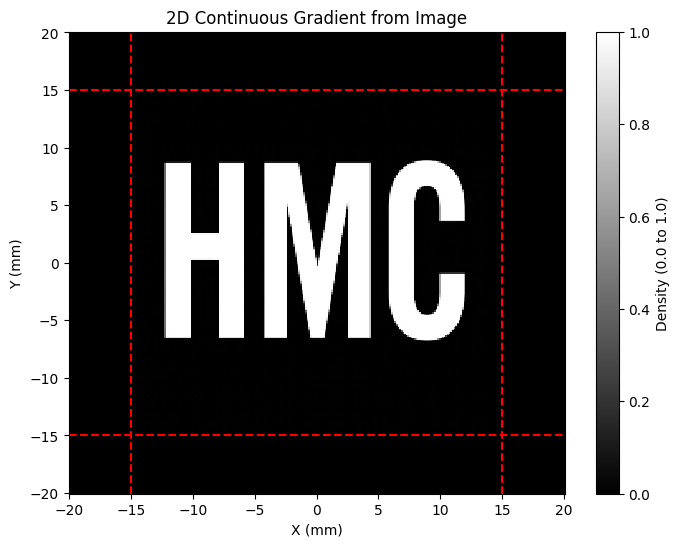

In [ ]:
import numpy as np
from PIL import Image
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt


def create_image_gradient(image_path, x_bounds, y_bounds):
    """
    Loads an image and maps its grayscale values (0.0 to 1.0) to a 2D coordinate space.
    """
    # Load image. If it has a transparent background, ensure it composites correctly
    # before converting to grayscale ('L').
    img = Image.open(image_path).convert("RGBA")
    background = Image.new("RGBA", img.size, (0, 0, 0, 255))
    composite = Image.alpha_composite(background, img)
    img_gray = composite.convert('L')

    # Convert to numpy array and normalize to [0.0, 1.0]
    # np.flipud is used because image origins are top-left, but math origins are bottom-left
    img_array = np.flipud(np.array(img_gray, dtype=np.float64) / 255.0)

    min_x, max_x = x_bounds
    min_y, max_y = y_bounds

    height, width = img_array.shape
    x_coords = np.linspace(min_x, max_x, width)
    y_coords = np.linspace(min_y, max_y, height)

    interpolator = RegularGridInterpolator(
        (y_coords, x_coords),
        img_array,
        bounds_error=False,
        fill_value=0.0
    )

    def gradient_func(x, y):
        return interpolator((y, x))

    return gradient_func

if __name__ == "__main__":
    # 1. Define your 4 corners in physical space
    X_CORNERS = (-15.0, 15.0)
    Y_CORNERS = (-15.0, 15.0)

    # 2. Point directly to your logo file
    # Make sure to use the exact name of your file
    my_gradient = create_image_gradient("/content/HMC_letters_logo.png", X_CORNERS, Y_CORNERS)

    # Visualize the continuous mathematical field
    # (Updated to nicely frame the -15 to 15 bounds)
    xx, yy = np.meshgrid(
        np.linspace(-20, 20, 300),
        np.linspace(-20, 20, 300)
    )

    zz = my_gradient(xx, yy)

    plt.figure(figsize=(8, 6))
    plt.pcolormesh(xx, yy, zz, cmap='gray', vmin=0, vmax=1)
    plt.colorbar(label='Density (0.0 to 1.0)')
    plt.title("2D Continuous Gradient from Image")
    plt.xlabel("X (mm)")
    plt.ylabel("Y (mm)")
    plt.axvline(X_CORNERS[0], color='r', linestyle='--')
    plt.axvline(X_CORNERS[1], color='r', linestyle='--')
    plt.axhline(Y_CORNERS[0], color='r', linestyle='--')
    plt.axhline(Y_CORNERS[1], color='r', linestyle='--')
    plt.show()

In [ ]:
import trimesh
import numpy as np

def scale_stl(input_path, output_path, scale_x, scale_y, scale_z):
    # Load the mesh
    mesh = trimesh.load(input_path)

    # Create a 4x4 transformation matrix for scaling
    transform_matrix = np.array([
        [scale_x, 0,       0,       0],
        [0,       scale_y, 0,       0],
        [0,       0,       scale_z, 0],
        [0,       0,       0,       1]
    ])

    # Apply the transformation
    mesh.apply_transform(transform_matrix)

    # Save the scaled mesh
    mesh.export(output_path)
    print(f"Saved scaled STL to: {output_path}")

if __name__ == "__main__":
    # Replace with your actual file paths
    INPUT_STL = "/content/30mmsquare1.STL"
    OUTPUT_STL = "/content/30mmsquare.STL"

    scale_stl(INPUT_STL, OUTPUT_STL, scale_x=1.0, scale_y=1.0, scale_z=0.1)

Saved scaled STL to: /content/30mmsquare.STL


In [ ]:
import trimesh
import numpy as np

def rotate_stl_y_to_z(input_path, output_path):
    print(f"Loading mesh from: {input_path}")
    mesh = trimesh.load(input_path)

    # Create a rotation matrix: 90 degrees (pi/2 radians) around the X-axis
    # This maps the +Y axis to the +Z axis.
    angle = np.pi / 2.0
    direction = [1, 0, 0] # Rotate around the X-axis
    center = [0, 0, 0]    # Rotate around the origin

    rotation_matrix = trimesh.transformations.rotation_matrix(angle, direction, center)

    # Apply the rotation to the mesh
    mesh.apply_transform(rotation_matrix)
    print("Mesh rotated 90 degrees around the X-axis.")

    # Export the newly rotated mesh
    mesh.export(output_path)
    print(f"Rotated mesh saved successfully to: {output_path}")

if __name__ == "__main__":
    # >>> REPLACE THESE WITH YOUR FILE PATHS <<<
    input_file = "/content/30mmsquare.STL"
    output_file = "/content/30mmsquare1.STL"

    rotate_stl_y_to_z(input_file, output_file)

Loading mesh from: /content/30mmsquare.STL
Mesh rotated 90 degrees around the X-axis.
Rotated mesh saved successfully to: /content/30mmsquare1.STL


In [ ]:
import cv2
import numpy as np
import math
from scipy.ndimage import distance_transform_edt, binary_opening
from skimage.morphology import skeletonize

def detect_and_fill_gaps(existing_lines, poly, res, nozzle, gap_threshold_mult=1.0, max_short_travel_mm=1.0):
    # 0. CRITICAL FIX: Convert generator to a solid list so it doesn't get consumed and vanish!
    if not existing_lines:
        return []
    existing_lines = list(existing_lines)

    minx, miny, maxx, maxy = poly.bounds
    pad = 1.0
    width = int((maxx - minx + 2 * pad) / res)
    height = int((maxy - miny + 2 * pad) / res)

    # 1. Rasterize Polygon Boundary Mask
    mask = np.zeros((height, width), dtype=np.uint8)
    if poly.exterior is None:
        return existing_lines

    poly_x, poly_y = poly.exterior.xy
    pix_px = ((np.array(poly_x) - (minx - pad)) / res).astype(int)
    pix_py = ((np.array(poly_y) - (miny - pad)) / res).astype(int)
    poly_pixel_pts = np.column_stack((pix_px, pix_py)).reshape((-1, 1, 2))
    cv2.fillPoly(mask, [poly_pixel_pts], color=255)

    # 2. Rasterize existing extrusion lines (This used to consume the generator!)
    canvas = np.zeros((height, width), dtype=np.uint8)
    line_thickness_px = max(1, int(round(nozzle / res)))

    for line in existing_lines:
        pts = np.array(line)
        if pts.ndim == 3: pts = np.squeeze(pts)
        if len(pts) == 0: continue

        pix_x = ((pts[:, 0] - (minx - pad)) / res).astype(int)
        pix_y = ((pts[:, 1] - (miny - pad)) / res).astype(int)
        pixel_pts = np.column_stack((pix_x, pix_y)).reshape((-1, 1, 2))
        cv2.polylines(canvas, [pixel_pts], isClosed=False, color=255, thickness=line_thickness_px)

    # 3. Compute distance field inside unprinted regions
    empty_space = ((mask == 255) & (canvas == 0)).astype(np.uint8)
    dist_field = distance_transform_edt(empty_space) * res

    # 4. Extract centerline skeleton for gaps
    gap_radius_threshold = nozzle * 0.25
    fill_mask = dist_field >= gap_radius_threshold
    fill_mask = binary_opening(fill_mask, structure=np.ones((3,3)))
    skel = skeletonize(fill_mask)

    # 5. Trace the pixels into gap lines
    gap_lines = trace_skeleton_to_lines(skel, minx, miny, res, pad, poly)

    def get_coords(geom):
        # Bulletproof coordinate extractor (handles Shapely, Lists, and OpenCV arrays safely)
        if hasattr(geom, 'coords'):
            return [list(pt) for pt in geom.coords]
        return [np.array(pt).flatten().tolist() for pt in geom]

    def point_dist(p1, p2):
        return math.hypot(p1[0] - p2[0], p1[1] - p2[1])

    # Start with all original lines, now safely preserved!
    all_lines = [get_coords(line) for line in existing_lines]

    # 6. Sort and append the new gap lines
    if gap_lines:
        unlinked_gaps = [get_coords(line) for line in gap_lines]
        current_gap = list(unlinked_gaps.pop(0))
        ordered_gaps = []

        while unlinked_gaps:
            best_idx = -1
            best_dist = float('inf')
            best_reverse = False

            end_pt = current_gap[-1]

            for i, nxt_line in enumerate(unlinked_gaps):
                d_start = point_dist(end_pt, nxt_line[0])
                d_end = point_dist(end_pt, nxt_line[-1])

                if d_start < best_dist:
                    best_dist = d_start; best_idx = i; best_reverse = False
                if d_end < best_dist:
                    best_dist = d_end; best_idx = i; best_reverse = True

            nxt_line = list(unlinked_gaps.pop(best_idx))
            if best_reverse:
                nxt_line.reverse()

            if best_dist <= max_short_travel_mm:
                current_gap.extend(nxt_line)
            else:
                ordered_gaps.append(current_gap)
                current_gap = nxt_line

        ordered_gaps.append(current_gap)
        all_lines.extend(ordered_gaps)

    if not all_lines:
        return []

    # 7. Final Pass: Bridge short travels across the ENTIRE print
    merged_all = []
    current_line = list(all_lines[0])

    for nxt_line in all_lines[1:]:
        end_pt = current_line[-1]
        start_pt = nxt_line[0]

        if point_dist(end_pt, start_pt) <= max_short_travel_mm:
            current_line.extend(list(nxt_line))
        else:
            merged_all.append(current_line)
            current_line = list(nxt_line)

    merged_all.append(current_line)

    # Return exactly the format that was passed in
    if hasattr(existing_lines[0], 'coords'):
        from shapely.geometry import LineString
        return [LineString(line) for line in merged_all if len(line) >= 2]
    elif isinstance(existing_lines[0], np.ndarray):
        return [np.array(line) for line in merged_all if len(line) >= 2]
    else:
        return [line for line in merged_all if len(line) >= 2]

In [ ]:
import numpy as np
import plotly.graph_objects as go
import cv2
import trimesh
from shapely.geometry import Polygon, LineString
from skimage import measure
from skimage.graph import MCP_Geometric
from scipy.ndimage import distance_transform_edt, gaussian_filter

# ==========================================
# 1. PARAMETERS (Removed the arbitrary CONTOUR_LEVELS)
# ==========================================
NOZZLE_DIA = 0.7 #0.35 -- 0.71
LAYER_HEIGHT = 0.08 #0.075
RESOLUTION = 0.02
GEOMETRIC_BIAS = 0.2

def density_function(x, y, z):
    # Volumetric density
    raw_field = my_gradient(x, y)
    return raw_field

# def density_function(x, y, z):
#     # Volumetric density
#     raw_field = np.sin(x / 2) * np.cos(z / 2) + x/4 + (z**2)/25 + np.sin(y)*np.sin(x / 2)
#     return raw_field


# ==========================================
# 2. GAP FILL ENGINE
# ==========================================
def generate_gap_fill(existing_lines, poly, res, nozzle):
    minx, miny, maxx, maxy = poly.bounds
    pad = 1.0
    width = int((maxx - minx + 2*pad) / res)
    height = int((maxy - miny + 2*pad) / res)

    mask = np.zeros((height, width), dtype=np.uint8)
    if poly.exterior is None: return []

    poly_x, poly_y = poly.exterior.xy
    pix_px = ((np.array(poly_x) - (minx - pad)) / res).astype(int)
    pix_py = ((np.array(poly_y) - (miny - pad)) / res).astype(int)
    poly_pixel_pts = np.column_stack((pix_px, pix_py)).reshape((-1, 1, 2))
    cv2.fillPoly(mask, [poly_pixel_pts], color=255)

    canvas = np.zeros((height, width), dtype=np.uint8)
    line_thickness_px = max(1, int(round(nozzle / res)))

    for line in existing_lines:
        pts = np.array(line)
        pix_x = ((pts[:, 0] - (minx - pad)) / res).astype(int)
        pix_y = ((pts[:, 1] - (miny - pad)) / res).astype(int)
        pixel_pts = np.column_stack((pix_x, pix_y)).reshape((-1, 1, 2))
        cv2.polylines(canvas, [pixel_pts], isClosed=False, color=255, thickness=line_thickness_px)

    empty_space = ((mask == 255) & (canvas == 0)).astype(np.uint8)
    dist_field = distance_transform_edt(empty_space) * res

    gap_lines = []
    max_gap = np.max(dist_field)
    gap_levels = list(np.arange(nozzle / 2.0, max_gap, nozzle))

    for lvl in gap_levels:
        contours = measure.find_contours(dist_field, lvl)
        for c in contours:
            path_x = minx - pad + (c[:, 1] * res)
            path_y = miny - pad + (c[:, 0] * res)
            line = LineString(np.column_stack((path_x, path_y)))
            intersection = poly.intersection(line)
            if intersection.is_empty: continue
            elif intersection.geom_type == 'LineString': gap_lines.append(list(intersection.coords))
            elif intersection.geom_type == 'MultiLineString':
                for geom in intersection.geoms: gap_lines.append(list(geom.coords))

    return [line for line in gap_lines if len(line) >= 2]

# ==========================================
# 3. MAIN 2D SLICER
# ==========================================
def generate_adaptive_isocontour_infill(poly, res, density_func, nozzle):
    minx, miny, maxx, maxy = poly.bounds
    pad = 1.0
    x = np.arange(minx - pad, maxx + pad, res)
    y = np.arange(miny - pad, maxy + pad, res)
    xx, yy = np.meshgrid(x, y)

    width_px, height_px = xx.shape[1], xx.shape[0]
    mask = np.zeros((height_px, width_px), dtype=np.uint8)
    poly_x, poly_y = poly.exterior.xy

    pix_px = ((np.array(poly_x) - (minx - pad)) / res).astype(int)
    pix_py = ((np.array(poly_y) - (miny - pad)) / res).astype(int)
    poly_pixel_pts = np.column_stack((pix_px, pix_py)).reshape((-1, 1, 2))
    cv2.fillPoly(mask, [poly_pixel_pts], color=255)

    NUM_ZONES = 6
    math_field = density_func(xx, yy)
    m_min, m_max = np.min(math_field), np.max(math_field)

    if m_max - m_min < 1e-6:
        math_norm = np.zeros_like(math_field)
    else:
        math_norm = (math_field - m_min) / (m_max - m_min)

    quantized = np.floor(math_norm * NUM_ZONES).astype(np.int32)
    quantized = np.clip(quantized, 0, NUM_ZONES - 1)

    edges = np.zeros_like(quantized, dtype=bool)
    edges[:-1, :] |= (quantized[:-1, :] != quantized[1:, :])
    edges[1:, :] |= (quantized[1:, :] != quantized[:-1, :])
    edges[:, :-1] |= (quantized[:, :-1] != quantized[:, 1:])
    edges[:, 1:] |= (quantized[:, 1:] != quantized[:, :-1])

    mask[edges] = 0
    geom_dist = distance_transform_edt(mask) * res
    max_dist = np.max(geom_dist)
    target_levels = np.arange(nozzle / 2.0, max_dist, nozzle)

    raw_lines = []

    # NEW: Setup a morphological kernel to eliminate tight pinches.
    # We enforce a minimum physical width between returning lines (0.75x nozzle).
    # If the space is narrower than this, it gets erased from the mask and the
    # contour cleanly cuts off, leaving the gap for the skeletonizer.
    min_loop_width = nozzle * 0.75
    kernel_radius = max(1, int((min_loop_width / 2.0) / res))
    kernel_size = kernel_radius * 2 + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

    for lvl in target_levels:
        # 1. Isolate the binary region valid for this specific contour level
        valid_mask = (geom_dist >= lvl).astype(np.uint8)

        # 2. Morphological opening erases narrow peninsulas (which cause the tight double-backs)
        opened_mask = cv2.morphologyEx(valid_mask, cv2.MORPH_OPEN, kernel)

        # 3. Create a temporary distance field clipped by this opened mask
        level_dist = np.copy(geom_dist)
        level_dist[opened_mask == 0] = 0

        # 4. Find contours on the cleaned field instead of the raw one
        contours = measure.find_contours(level_dist, lvl)

        for c in contours:
            path_x = minx - pad + (c[:, 1] * res)
            path_y = miny - pad + (c[:, 0] * res)
            line = LineString(np.column_stack((path_x, path_y))).simplify(tolerance=res/4.0, preserve_topology=True)

            intersection = poly.intersection(line)
            if intersection.is_empty: continue
            elif intersection.geom_type == 'LineString': raw_lines.append(list(intersection.coords))
            elif intersection.geom_type == 'MultiLineString':
                for geom in intersection.geoms: raw_lines.append(list(geom.coords))

    raw_lines = [line for line in raw_lines if len(line) >= 2]

    # Store the raw lines before any post-processing is applied
    original_raw_lines = list(raw_lines)

    # Run post-processing pass (gap detection + segment subdivision)
    MAX_SEG_LEN = 5.0
    GAP_MULT = 1.0

    all_lines = post_process_layer_paths(
        raw_lines, poly, res, nozzle,
        max_segment_length=MAX_SEG_LEN, gap_threshold_mult=GAP_MULT
    )

    if not all_lines: return original_raw_lines, []

    # ==========================================
    # 5. Strict Zone-Based Path Routing
    # ==========================================
    lines_with_zones = []
    for line in all_lines:
        mid_pt = line[len(line) // 2]
        d = density_func(mid_pt[0], mid_pt[1])

        if m_max - m_min < 1e-6:
            zone = 0
        else:
            n = (d - m_min) / (m_max - m_min)
            zone = int(np.clip(np.floor(n * NUM_ZONES), 0, NUM_ZONES - 1))

        lines_with_zones.append((zone, line))

    ordered_lines = []
    unique_zones = sorted(list(set(z for z, l in lines_with_zones)))

    for z in unique_zones:
        unvisited = [l for zone, l in lines_with_zones if zone == z]
        if not unvisited: continue

        if not ordered_lines:
            ordered_lines.append(unvisited.pop(0))

        while unvisited:
            last_pt = np.array(ordered_lines[-1][-1])
            best_dist = float('inf')
            best_idx, reverse_line = -1, False

            for i, line in enumerate(unvisited):
                start_pt, end_pt = np.array(line[0]), np.array(line[-1])
                dist_to_start = np.linalg.norm(start_pt - last_pt)
                dist_to_end = np.linalg.norm(end_pt - last_pt)

                if dist_to_start < best_dist:
                    best_dist, best_idx, reverse_line = dist_to_start, i, False
                if dist_to_end < best_dist:
                    best_dist, best_idx, reverse_line = dist_to_end, i, True

            next_line = unvisited.pop(best_idx)
            if reverse_line: next_line = next_line[::-1]
            ordered_lines.append(next_line)

    return original_raw_lines, ordered_lines

# ==========================================
# 4. Z-AXIS SLICING & MATRIX MAPPING
# ==========================================
def slice_and_generate_paths(mesh_path):
    print(f"Loading mesh: {mesh_path}")
    mesh = trimesh.load(mesh_path)

    min_b, max_b = mesh.bounds
    center_x = (min_b[0] + max_b[0]) / 2.0
    center_y = (min_b[1] + max_b[1]) / 2.0
    min_z = min_b[2]

    mesh.apply_translation([-center_x, -center_y, -min_z])
    z_max = mesh.bounds[1][2]
    z_levels = np.arange(LAYER_HEIGHT / 2.0, z_max, LAYER_HEIGHT)

    global_raw_lines = []
    global_ordered_lines = []

    for z in z_levels:
        print(f"Slicing layer at Z: {z:.2f}")
        slice_3d = mesh.section(plane_origin=[0, 0, z], plane_normal=[0, 0, 1])
        if slice_3d is None: continue

        slice_2d, to_3d = slice_3d.to_2D()
        polygons = slice_2d.polygons_full

        def planar_density_func(u, v):
            u_arr, v_arr = np.atleast_1d(u), np.atleast_1d(v)
            shape = np.shape(u)
            pts_2d = np.column_stack((u_arr.ravel(), v_arr.ravel()))
            pts_2d_hom = np.column_stack((pts_2d, np.zeros(len(pts_2d)), np.ones(len(pts_2d))))
            pts_3d = (to_3d @ pts_2d_hom.T).T
            res = density_function(pts_3d[:, 0], pts_3d[:, 1], pts_3d[:, 2])
            return res[0] if not shape else res.reshape(shape)

        for poly in polygons:
            raw_2d, processed_2d = generate_adaptive_isocontour_infill(poly, RESOLUTION, planar_density_func, NOZZLE_DIA)

            # Map raw lines back to 3D
            for line in raw_2d:
                pts_2d = np.array(line)
                pts_2d_hom = np.column_stack((pts_2d, np.zeros(len(pts_2d)), np.ones(len(pts_2d))))
                pts_3d = (to_3d @ pts_2d_hom.T).T[:, :3]
                global_raw_lines.append(pts_3d.tolist())

            # Map processed lines back to 3D
            for line in processed_2d:
                pts_2d = np.array(line)
                pts_2d_hom = np.column_stack((pts_2d, np.zeros(len(pts_2d)), np.ones(len(pts_2d))))
                pts_3d = (to_3d @ pts_2d_hom.T).T[:, :3]
                global_ordered_lines.append(pts_3d.tolist())

    return global_raw_lines, global_ordered_lines

# ==========================================
# 5. VISUALIZATION
# ==========================================
if __name__ == "__main__":
    raw_lines, processed_lines = slice_and_generate_paths("/content/30mmsquare.STL")

    fig = go.Figure()

    def add_lines_to_plot(lines, name, visible=True, show_travels=True):
        if not lines: return
        ext_x, ext_y, ext_z, ext_color = [], [], [], []
        travel_x, travel_y, travel_z = [], [], []

        for i, line in enumerate(lines):
            line_arr = np.array(line)
            densities = density_function(line_arr[:, 0], line_arr[:, 1], line_arr[:, 2])

            ext_x.extend(line_arr[:, 0].tolist() + [None])
            ext_y.extend(line_arr[:, 1].tolist() + [None])
            ext_z.extend(line_arr[:, 2].tolist() + [None])
            ext_color.extend(densities.tolist() + [0])

            if i < len(lines) - 1 and show_travels:
                next_line = lines[i+1]
                start_jump, end_jump = line_arr[-1], np.array(next_line[0])
                travel_x.extend([start_jump[0], end_jump[0], None])
                travel_y.extend([start_jump[1], end_jump[1], None])
                travel_z.extend([start_jump[2], end_jump[2], None])

        max_abs_density = max(abs(np.nanmin(ext_color)), abs(np.nanmax(ext_color)))
        if max_abs_density == 0: max_abs_density = 1

        fig.add_trace(go.Scatter3d(
            x=ext_x, y=ext_y, z=ext_z,
            mode='lines',
            visible=visible,
            line=dict(
                color=ext_color,
                colorscale=[[0, 'red'], [0.5, 'black'], [1, 'yellow']],
                cmin=-max_abs_density, cmax=max_abs_density, width=6
            ),
            name=f'{name} (Extrusion)'
        ))

        if show_travels:
            fig.add_trace(go.Scatter3d(
                x=travel_x, y=travel_y, z=travel_z,
                mode='lines', visible=visible,
                line=dict(color='blue', width=2),
                name=f'{name} (Travel)'
            ))

    # Add Raw Paths (Hidden by default, toggle in the legend)
    add_lines_to_plot(raw_lines, "Before Post-Processing", visible='legendonly', show_travels=False)

    # Add Processed Paths (Visible by default)
    add_lines_to_plot(processed_lines, "After Post-Processing", visible=True, show_travels=True)

    fig.update_layout(
        title="3D Volumetric Slicer - Click Legend to Toggle Before/After",
        scene=dict(
            xaxis_title='X (mm)', yaxis_title='Y (mm)', zaxis_title='Z (Height)',
            bgcolor='rgb(150, 150, 150)', aspectmode='data'
        ),
        paper_bgcolor='rgb(20, 20, 20)', font=dict(color='white'), showlegend=True
    )
    fig.show()
# ==========================================
# 5. VISUALIZATION
# ==========================================
if __name__ == "__main__":
    # Unpack both the raw and processed lines returned by the updated function
    raw_lines, processed_lines = slice_and_generate_paths("/content/30mmsquare.STL")

    fig = go.Figure()

    def add_lines_to_plot(lines, name, visible=True, show_travels=True):
        if not lines: return
        ext_x, ext_y, ext_z, ext_color = [], [], [], []
        travel_x, travel_y, travel_z = [], [], []

        for i, line in enumerate(lines):
            line_arr = np.array(line)
            densities = density_function(line_arr[:, 0], line_arr[:, 1], line_arr[:, 2])

            ext_x.extend(line_arr[:, 0].tolist() + [None])
            ext_y.extend(line_arr[:, 1].tolist() + [None])
            ext_z.extend(line_arr[:, 2].tolist() + [None])
            ext_color.extend(densities.tolist() + [0])

            if i < len(lines) - 1 and show_travels:
                next_line = lines[i+1]
                start_jump, end_jump = line_arr[-1], np.array(next_line[0])
                travel_x.extend([start_jump[0], end_jump[0], None])
                travel_y.extend([start_jump[1], end_jump[1], None])
                travel_z.extend([start_jump[2], end_jump[2], None])

        max_abs_density = max(abs(np.nanmin(ext_color)), abs(np.nanmax(ext_color)))
        if max_abs_density == 0: max_abs_density = 1

        fig.add_trace(go.Scatter3d(
            x=ext_x, y=ext_y, z=ext_z,
            mode='lines',
            visible=visible,
            line=dict(
                color=ext_color,
                colorscale=[[0, 'red'], [0.5, 'black'], [1, 'yellow']],
                cmin=-max_abs_density, cmax=max_abs_density, width=6
            ),
            name=f'{name} (Extrusion)'
        ))

        if show_travels:
            fig.add_trace(go.Scatter3d(
                x=travel_x, y=travel_y, z=travel_z,
                mode='lines', visible=visible,
                line=dict(color='blue', width=2),
                name=f'{name} (Travel)'
            ))

    # Add Raw Paths (Hidden by default, toggle by clicking in the legend)
    add_lines_to_plot(raw_lines, "Before Post-Processing", visible='legendonly', show_travels=False)

    # Add Processed Paths (Visible by default)
    add_lines_to_plot(processed_lines, "After Post-Processing", visible=True, show_travels=True)

    fig.update_layout(
        title="3D Volumetric Slicer - Click Legend to Toggle Before/After",
        scene=dict(
            xaxis_title='X (mm)', yaxis_title='Y (mm)', zaxis_title='Z (Height)',
            bgcolor='rgb(150, 150, 150)', aspectmode='data'
        ),
        paper_bgcolor='rgb(20, 20, 20)', font=dict(color='white'), showlegend=True
    )
    fig.show()

Loading mesh: /content/30mmsquare.STL
Slicing layer at Z: 0.04


Loading mesh: /content/30mmsquare.STL
Slicing layer at Z: 0.04


In [ ]:
# ==========================================
# 6. DUET 3 REPRAP G-CODE GENERATOR
# ==========================================
import numpy as np

def export_gcode(ordered_lines, filename="output.gcode", flowrate_mm3_per_s=2.0, travel_speed_mm_s=100.0, offset=(88.563, 46.587)):
    from scipy.spatial import cKDTree
    from collections import defaultdict

    print(f"Generating G-code -> {filename}")

    # Variables you might need to define if they aren't globally scoped
    # NOZZLE_DIA = 0.4
    # LAYER_HEIGHT = 0.2

    # Convert mm/s to mm/min for G-code F parameters
    travel_speed_mm_min = travel_speed_mm_s * 60.0

    # 1. Pre-process paths: Group by layer, map XYZ, and apply the XY offset
    mapped_paths = []
    layers = defaultdict(list)

    offset_x, offset_y = offset

    for p_idx, path in enumerate(ordered_lines):
        m_path = []
        for pt in path:
            # Apply the offset mathematically so coordinates remain positive
            m_path.append([pt[0] + offset_x, pt[1] + offset_y, pt[2]])
        mapped_paths.append(m_path)

        if m_path:
            z_val = round(m_path[0][2], 4)
            layers[z_val].append((p_idx, m_path))

    # 2. Build Spatial KD-Trees for each layer to find line spacing
    layer_kdtrees = {}
    layer_point_info = {} # Maps KDTree index to (global_path_idx, point_idx)

    print("Building spatial trees for line thickness calculation...")
    for z_val, paths_in_layer in layers.items():
        pts = []
        info = []
        for p_idx, path in paths_in_layer:
            for pt_idx, pt in enumerate(path):
                pts.append([pt[0], pt[1]]) # 2D KD-Tree for the layer (X, Y)
                info.append((p_idx, pt_idx))

        if pts:
            layer_kdtrees[z_val] = cKDTree(pts)
            layer_point_info[z_val] = info

    # 3. Write G-code
    gcode = [
        "; RepRap G-Code generated for Duet 3",
        "; NOTE: Standard XYZ mapping (Z is height)",
        "; EXTRUSION: Externally managed (No E parameters)",
        f"; Constant Volumetric Flowrate: {flowrate_mm3_per_s} mm^3/s",
        f"; Offset Applied: X+{offset_x:.3f} Y+{offset_y:.3f}",
        "",
        "; --- STARTING SEQUENCE ---",
        "M201 X500 Y500 Z100 ; Set max acceleration",
        "M203 X30000 Y30000 Z300 ; Set max feedrate",
        "M204 P500 T500 ; Set print and travel accelerations",
        "M566 X480.00 Y480.00 Z24.00 ; Set jerk",
        "G90 ; Absolute positioning",
        "G21 ; Set units to millimeters",
        "G92 Z0 ; Reset Z position",
        "G1 Z30 F600 ; Move Z up to clear petri dish",
        "G28 X Y ; Home X and Y",
        "G28 Z ; Home Z",
        "M400 ; Wait for current moves to finish",
        "G92 Z0 ; Reset Z position",
        "G1 Z30 F600 ; Move Z up to safe height",
        f"G1 X{offset_x:.3f} Y{offset_y:.3f} F3000 ; Move to starting position (center of dish)",
        "; --- END STARTING SEQUENCE ---",
        ""
    ]

    global_time = 0.0
    last_time_tick = -1
    sync_id = 0  # This will purely count up 0, 1, 2, 3...
    last_pos = None  # (x, y, z)

    for p_idx, path in enumerate(mapped_paths):
        if len(path) < 2: continue

        start_x, start_y, start_z = path[0]

        # TRAVEL MOVE WITH Z-HOP
        if last_pos is not None:
            dist_z = 1.0
            dist_xy = np.linalg.norm([start_x - last_pos[0], start_y - last_pos[1]])
            travel_time = ((dist_z * 2) + dist_xy) / travel_speed_mm_s

            gcode.append(f"G0 Z{last_pos[2] + 1.0:.4f} F{travel_speed_mm_min:.1f} ; Z-hop up")
            gcode.append(f"G0 X{start_x:.4f} Y{start_y:.4f} F{travel_speed_mm_min:.1f} ; Travel to new path")
            gcode.append(f"G0 Z{start_z:.4f} F{travel_speed_mm_min:.1f} ; Z-hop down")

            global_time += travel_time

            # Check if 2 seconds have passed; if so, print sequential ID
            current_time_tick = int(global_time / 0.7)
            if current_time_tick > last_time_tick:
                last_time_tick = current_time_tick
                gcode.append(f'M118 P0 S"{sync_id}" ; Sync timer (Travel)')
                sync_id += 1
        else:
            gcode.append(f"G0 X{start_x:.4f} Y{start_y:.4f} Z{start_z:.4f} F{travel_speed_mm_min:.1f} ; Initial approach")

        # EXTRUSION MOVES
        layer_z = round(start_z, 4)
        kdtree = layer_kdtrees.get(layer_z)
        pt_info = layer_point_info.get(layer_z)

        for i in range(1, len(path)):
            p1, p2 = path[i-1], path[i]
            x1, y1, z1 = p1
            x2, y2, z2 = p2

            dist = np.linalg.norm([x2-x1, y2-y1, z2-z1])
            if dist < 1e-5: continue

            # Find the actual physical spacing to the nearest adjacent line
            line_thickness = NOZZLE_DIA # Default fallback

            if kdtree:
                mid_x, mid_y = (x1 + x2) / 2.0, (y1 + y2) / 2.0

                dists, idxs = kdtree.query([mid_x, mid_y], k=min(15, len(pt_info)))

                if isinstance(dists, float):
                    dists, idxs = [dists], [idxs]

                for d, nearest_idx in zip(dists, idxs):
                    found_p_idx, found_pt_idx = pt_info[nearest_idx]

                    if found_p_idx == p_idx and abs(found_pt_idx - i) < 10:
                        continue

                    if d > 0.01:
                        line_thickness = d
                        break

            # Clamp thickness to realistic physical limits
            line_thickness = max(NOZZLE_DIA * 0.5, min(line_thickness, NOZZLE_DIA * 3.0))

            # Speed = Volumetric Flow / Area
            area = line_thickness * LAYER_HEIGHT
            v_mm_s = flowrate_mm3_per_s / area
            feedrate_mm_min = v_mm_s * 60.0
            dt = dist / v_mm_s

            # Check if 2 seconds have passed; if so, print sequential ID
            current_time_tick = int((global_time + dt) / 0.7)
            if current_time_tick > last_time_tick:
                last_time_tick = current_time_tick
                gcode.append(f'M118 P0 S"{sync_id}" ; Sync timer')
                sync_id += 1

            global_time += dt

            # Extrusion move
            gcode.append(f"G1 X{x2:.4f} Y{y2:.4f} Z{z2:.4f} F{feedrate_mm_min:.1f} ; Width: {line_thickness:.3f}mm")

            last_pos = (x2, y2, z2)

    with open(filename, 'w') as f:
        f.write("\n".join(gcode))

    print(f"G-code saved! Estimated theoretical print time: {global_time:.1f} seconds. Total Syncs: {sync_id}")

export_gcode(processed_lines, filename="output.gcode", flowrate_mm3_per_s=2.4, travel_speed_mm_s=100.0) #feedrate 0.05

Generating G-code -> output.gcode
Building spatial trees for line thickness calculation...
G-code saved! Estimated theoretical print time: 77.5 seconds. Total Syncs: 111
